# Baseline UNet - Hugo

Segmentation supervisée sur ACDC (4 classes : fond, VD, myocarde, VG).
UNet + augmentation (rotation/zoom) + perte CE + Dice.

In [2]:
import os, random, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms.functional as TF
import matplotlib.pyplot as plt

# paramètres
MODEL_NAME = 'Hugo_baseline'
EPOCHS = 30
BATCH_SIZE = 8
LR = 1e-3
WEIGHT_DECAY = 1e-4
BASE_CHANNELS = 16
SEED = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device :', device)

DATA_DIR = os.path.join('./Data', 'Data')
print('Données :', DATA_DIR)

Device : cuda
Données : ./Data\Data


In [3]:
# chargement des données
def list_pairs(split):
    img_dir = os.path.join(DATA_DIR, split, 'Img')
    gt_dir = os.path.join(DATA_DIR, split, 'GT')
    # on garde seulement les .png (il y a des .DS_Store dans les dossiers)
    imgs = sorted(f for f in os.listdir(img_dir) if f.endswith('.png'))
    gts = sorted(f for f in os.listdir(gt_dir) if f.endswith('.png'))
    return [(os.path.join(img_dir, a), os.path.join(gt_dir, b)) for a, b in zip(imgs, gts)]

class ACDCDataset(Dataset):
    def __init__(self, split, augment=False):
        self.pairs = list_pairs(split)
        self.augment = augment

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, i):
        img = Image.open(self.pairs[i][0]).convert('L')
        mask = Image.open(self.pairs[i][1]).convert('L')
        # augmentation : rotation + zoom, la même pour l'image et le masque
        if self.augment and random.random() < 0.8:
            angle = random.uniform(-15, 15)
            scale = random.uniform(0.9, 1.1)
            img = TF.affine(img, angle=angle, translate=[0, 0], scale=scale, shear=[0.0],
                            interpolation=TF.InterpolationMode.BILINEAR)
            mask = TF.affine(mask, angle=angle, translate=[0, 0], scale=scale, shear=[0.0],
                             interpolation=TF.InterpolationMode.NEAREST)
        x = torch.from_numpy(np.array(img, dtype=np.float32) / 255.0).unsqueeze(0)
        # masque : 0, 85, 170, 255 -> classes 0, 1, 2, 3
        y = torch.from_numpy(np.clip(np.round(np.array(mask, dtype=np.float32) / 85.0), 0, 3).astype(np.int64))
        return x, y

train_set = ACDCDataset('train', augment=True)
val_set = ACDCDataset('val')
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False)
print('Train :', len(train_set), 'images | Val :', len(val_set), 'images')
x, y = train_set[0]
print('Image', tuple(x.shape), '| classes présentes dans le masque :', torch.unique(y).tolist())

Train : 204 images | Val : 74 images
Image (1, 256, 256) | classes présentes dans le masque : [0]


In [4]:
# modèle UNet (2 convolutions par bloc, 4 niveaux)
def double_conv(cin, cout):
    return nn.Sequential(
        nn.Conv2d(cin, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
        nn.Conv2d(cout, cout, 3, padding=1), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class UNet(nn.Module):
    def __init__(self, num_classes=4, c=16):
        super().__init__()
        self.enc1, self.enc2 = double_conv(1, c), double_conv(c, 2 * c)
        self.enc3, self.enc4 = double_conv(2 * c, 4 * c), double_conv(4 * c, 8 * c)
        self.center = nn.Sequential(double_conv(8 * c, 16 * c), nn.Dropout2d(0.3))
        self.up4, self.dec4 = nn.ConvTranspose2d(16 * c, 8 * c, 2, stride=2), double_conv(16 * c, 8 * c)
        self.up3, self.dec3 = nn.ConvTranspose2d(8 * c, 4 * c, 2, stride=2), double_conv(8 * c, 4 * c)
        self.up2, self.dec2 = nn.ConvTranspose2d(4 * c, 2 * c, 2, stride=2), double_conv(4 * c, 2 * c)
        self.up1, self.dec1 = nn.ConvTranspose2d(2 * c, c, 2, stride=2), double_conv(2 * c, c)
        self.final = nn.Conv2d(c, num_classes, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(F.max_pool2d(e1, 2))
        e3 = self.enc3(F.max_pool2d(e2, 2))
        e4 = self.enc4(F.max_pool2d(e3, 2))
        m = self.center(F.max_pool2d(e4, 2))
        d4 = self.dec4(torch.cat([self.up4(m), e4], 1))
        d3 = self.dec3(torch.cat([self.up3(d4), e3], 1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], 1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], 1))
        return self.final(d1)

net = UNet(4, BASE_CHANNELS).to(device)
print('Paramètres : {:,}'.format(sum(p.numel() for p in net.parameters())))

Paramètres : 1,943,812


In [5]:
# perte CE + Dice et calcul du Dice par classe
CLASS_NAMES = ['VD', 'Myo', 'VG']

def dice_loss(logits, target, eps=1e-6):
    probs = torch.softmax(logits, dim=1)
    onehot = F.one_hot(target, logits.shape[1]).permute(0, 3, 1, 2).float()
    inter = (probs * onehot).sum(dim=(0, 2, 3))
    union = probs.sum(dim=(0, 2, 3)) + onehot.sum(dim=(0, 2, 3))
    dice = (2 * inter + eps) / (union + eps)
    return 1 - dice[1:].mean()  # sans le fond

ce = nn.CrossEntropyLoss()
def loss_fn(logits, target):
    return ce(logits, target) + dice_loss(logits, target)

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    inter, total, losses = np.zeros(4), np.zeros(4), []
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        out = model(x)
        losses.append(loss_fn(out, y).item())
        pred = out.argmax(1)
        for k in range(1, 4):
            p, g = pred == k, y == k
            inter[k] += (p & g).sum().item()
            total[k] += p.sum().item() + g.sum().item()
    dice = 2 * inter[1:] / np.maximum(total[1:], 1)
    return float(np.mean(losses)), dice

In [6]:
# entraînement
optimizer = torch.optim.Adam(net.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
os.makedirs(os.path.join('models', MODEL_NAME), exist_ok=True)
best_path = os.path.join('models', MODEL_NAME, 'best.pth')

history = {'train_loss': [], 'val_loss': [], 'val_dice': []}
best_dice, best_epoch = -1, -1
for epoch in range(EPOCHS):
    t0 = time.time()
    net.train()
    losses = []
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = loss_fn(net(x), y)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    scheduler.step()

    val_loss, val_dice = evaluate(net, val_loader)
    history['train_loss'].append(np.mean(losses))
    history['val_loss'].append(val_loss)
    history['val_dice'].append(val_dice)
    mean_dice = val_dice.mean()
    flag = ''
    if mean_dice > best_dice:
        best_dice, best_epoch = mean_dice, epoch
        torch.save(net.state_dict(), best_path)
        flag = '  <- meilleur'
    print('Époque {:2d} | loss train {:.3f} val {:.3f} | Dice VD {:.3f} Myo {:.3f} VG {:.3f} | moy {:.3f} | {:.0f}s{}'.format(
        epoch, np.mean(losses), val_loss, *val_dice, mean_dice, time.time() - t0, flag))

print('\nMeilleur Dice moyen en validation : {:.3f} (époque {})'.format(best_dice, best_epoch))

Époque  0 | loss train 2.007 val 1.983 | Dice VD 0.002 Myo 0.000 VG 0.010 | moy 0.004 | 3s  <- meilleur
Époque  1 | loss train 1.720 val 1.828 | Dice VD 0.000 Myo 0.000 VG 0.079 | moy 0.026 | 2s  <- meilleur
Époque  2 | loss train 1.549 val 1.511 | Dice VD 0.000 Myo 0.000 VG 0.427 | moy 0.142 | 2s  <- meilleur
Époque  3 | loss train 1.400 val 1.571 | Dice VD 0.000 Myo 0.000 VG 0.163 | moy 0.054 | 2s
Époque  4 | loss train 1.272 val 1.204 | Dice VD 0.011 Myo 0.393 VG 0.554 | moy 0.319 | 2s  <- meilleur
Époque  5 | loss train 1.163 val 1.157 | Dice VD 0.000 Myo 0.334 VG 0.552 | moy 0.295 | 2s
Époque  6 | loss train 1.056 val 1.126 | Dice VD 0.000 Myo 0.167 VG 0.467 | moy 0.212 | 2s
Époque  7 | loss train 0.969 val 0.962 | Dice VD 0.009 Myo 0.564 VG 0.721 | moy 0.431 | 2s  <- meilleur
Époque  8 | loss train 0.889 val 1.049 | Dice VD 0.203 Myo 0.184 VG 0.515 | moy 0.301 | 2s
Époque  9 | loss train 0.803 val 0.817 | Dice VD 0.496 Myo 0.608 VG 0.779 | moy 0.628 | 2s  <- meilleur
Époque 10 | 

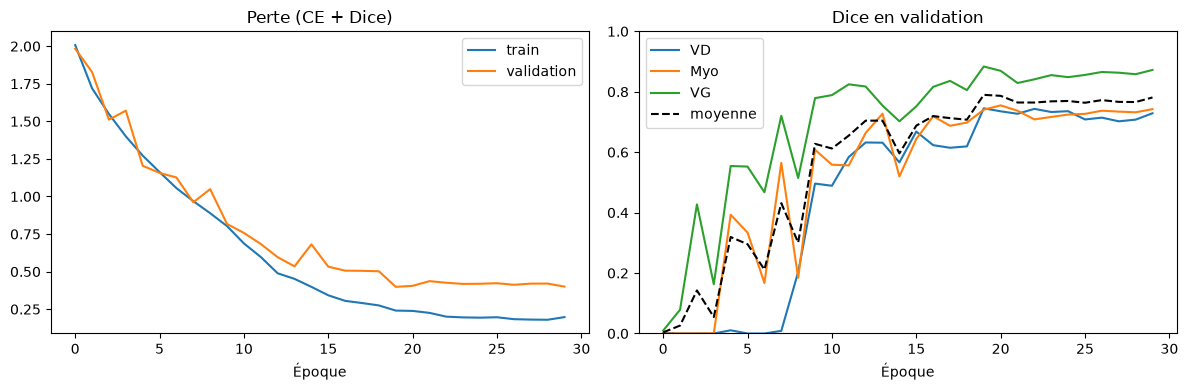

In [7]:
# courbes
vd = np.array(history['val_dice'])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history['train_loss'], label='train'); ax[0].plot(history['val_loss'], label='validation')
ax[0].set_title('Perte (CE + Dice)'); ax[0].set_xlabel('Époque'); ax[0].legend()
for k, name in enumerate(CLASS_NAMES):
    ax[1].plot(vd[:, k], label=name)
ax[1].plot(vd.mean(1), 'k--', label='moyenne')
ax[1].set_title('Dice en validation'); ax[1].set_xlabel('Époque'); ax[1].set_ylim(0, 1); ax[1].legend()
plt.tight_layout(); plt.show()

Meilleur modèle | Dice VD 0.745  Myo 0.741  VG 0.884 | moyenne 0.790


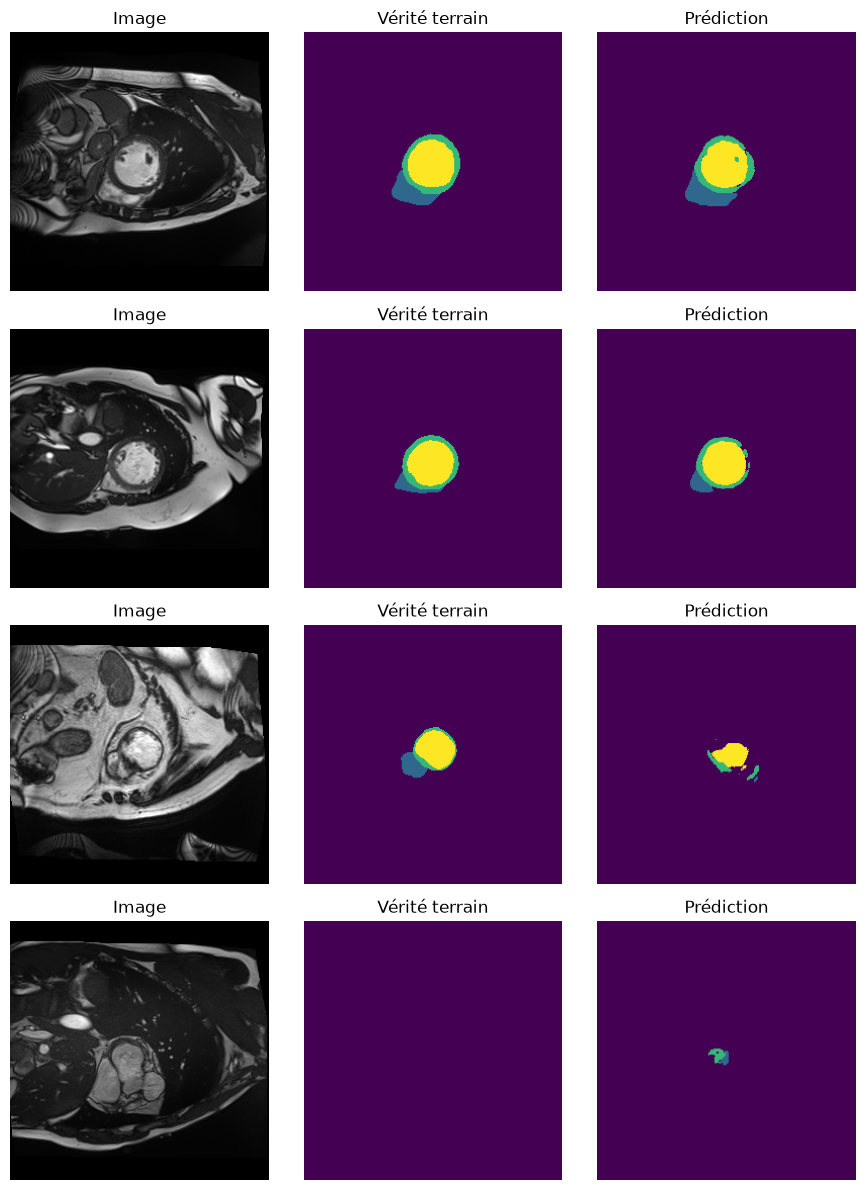

In [8]:
# résultat du meilleur modèle + quelques exemples
net.load_state_dict(torch.load(best_path, map_location=device))
_, dice = evaluate(net, val_loader)
print('Meilleur modèle | Dice VD {:.3f}  Myo {:.3f}  VG {:.3f} | moyenne {:.3f}'.format(*dice, dice.mean()))

net.eval()
idx = [5, 25, 45, 65]
fig, ax = plt.subplots(len(idx), 3, figsize=(9, 3 * len(idx)))
with torch.no_grad():
    for r, i in enumerate(idx):
        x, y = val_set[i]
        pred = net(x.unsqueeze(0).to(device)).argmax(1)[0].cpu()
        ax[r, 0].imshow(x[0], cmap='gray'); ax[r, 0].set_title('Image')
        ax[r, 1].imshow(y, vmin=0, vmax=3, cmap='viridis'); ax[r, 1].set_title('Vérité terrain')
        ax[r, 2].imshow(pred, vmin=0, vmax=3, cmap='viridis'); ax[r, 2].set_title('Prédiction')
        for a in ax[r]: a.axis('off')
plt.tight_layout(); plt.show()